# Netflix reviews – data cleaning

This notebook turns the raw Google Play reviews into four files:

| File | Content | Used for |
| --- | --- | --- |
| `netflix_reviews_ratings.csv` | every review from the chosen years | star ratings |
| `netflix_reviews_clean_full.csv` | every clean English review | text analysis |
| `netflix_reviews_to_annotate.csv` | clean English reviews with 10 or more words, without duplicates | annotation set |
| `netflix_sample_to_annotate.csv` | random sample of the annotation set (same number per year) | automatic annotation |

Every step follows the same pattern: **why** the step is needed, **look** at the data, **decide and apply**, then **check** what was removed.

## 0. Setup

In [1]:
import re
import pandas as pd
import matplotlib.pyplot as plt
import nltk
from nltk.corpus import words
from fast_langdetect import detect

pd.set_option('display.max_colwidth', 120)

In [54]:
FILE_PATH = './netflix_reviews_raw.csv'
APP_NAME = 'netflix'
YEARS_TO_KEEP = [2022, 2023, 2026]

MIN_REAL_WORD_RATIO = 0.6     # dictionary check (section 5b)
MIN_WORDS = 10                # annotation set (section 8)

SAMPLE_SIZE = 5000            # per app -> 10,000 reviews in total for both apps
HAND_SIZE = 50                                        # per app -> 100 reviews to annotate by hand
HAND_FILE = f'{APP_NAME}_human_annotation.xlsx'
RANDOM_SEED = 42

### Helpers
`log_step` records how many reviews are left after each step, overall and per year.
`show_removed` prints how many reviews a step removed and shows a random sample of them, so every cut can be checked by eye.

In [3]:
cleaning_log = []
year_log = []

def log_step(step_name, data):
    cleaning_log.append((step_name, len(data)))
    year_log.append(data['year'].value_counts().sort_index().rename(step_name))
    print(f"{step_name}: {len(data):,} reviews left")

def show_removed(before, after, n=10):
    removed = before[~before['reviewId'].isin(after['reviewId'])]
    print(f"Removed: {len(removed):,} reviews ({len(removed) / len(before) * 100:.1f}%)")
    if len(removed) > 0:
        return removed[['content', 'score', 'year']].sample(min(n, len(removed)), random_state=1)

## 1. First look at the raw data
**Why:** before cleaning, we need to know what the file contains: which columns, how many missing values, and which years the reviews cover.

In [6]:
df_raw = pd.read_csv(FILE_PATH)
print(df_raw.shape)
df_raw.head(3)

(393079, 13)


,reviewId,userName,userImage,content,score,thumbsUpCount,reviewCreatedVersion,at,replyContent,repliedAt,appVersion,app,extracted_on
0,6b29edf4-485e-45f2-b8e6-10ab4c931121,Aphiwe Combo,https://play-lh.googleusercontent.com/a/ACg8ocLJqRNueXrDgX_1zn82jrWCdHXlMVAbtRUvSOMpJRcWvW5cYg=mo,awesome 👌 thank you 👏,1,0,9.93.0 build 8 74808,2026-11-25 08:28:06,NaN,NaN,9.93.0 build 8 74808,netflix,2026-11-26
1,02ef1921-cd6e-4adb-a35c-94e62b7381b9,Sahil Khan,https://play-lh.googleusercontent.com/a-/ALV-UjWMe01uCtm-1xSdvfsIcZ7K_doxz7oT4lUGREXwmR0W83huxhCmDQ,Application Didn't open You Should pay ₹499 Mandatory for just open/Login on this application after Install,1,0,9.93.0 build 8 74808,2026-11-25 08:04:38,NaN,NaN,9.93.0 build 8 74808,netflix,2026-11-26
2,a9a60cdd-ce2a-4a23-85e7-6cd81564bfa7,Reva Lemmon,https://play-lh.googleusercontent.com/a/ACg8ocLW8yDcGHIAA0I2poMfzpAjAjWjKJl4FEplLbPZBmkfZEnqsQ=mo,it does not work,1,0,9.93.0 build 8 74808,2026-11-25 07:16:28,NaN,NaN,9.93.0 build 8 74808,netflix,2026-11-26


In [7]:
print(df_raw.isna().sum())

reviewId                     0
userName                     3
userImage                    0
content                     61
score                        0
thumbsUpCount                0
reviewCreatedVersion    101180
at                           0
replyContent            393079
repliedAt               393079
appVersion              101180
app                          0
extracted_on                 0
dtype: int64


In [8]:
df_raw['at'] = pd.to_datetime(df_raw['at'], errors='coerce')
df_raw['year'] = df_raw['at'].dt.year
print("First review:", df_raw['at'].min())
print("Last review: ", df_raw['at'].max())

First review: 2022-01-01 00:04:10
Last review:  2026-11-25 08:51:30


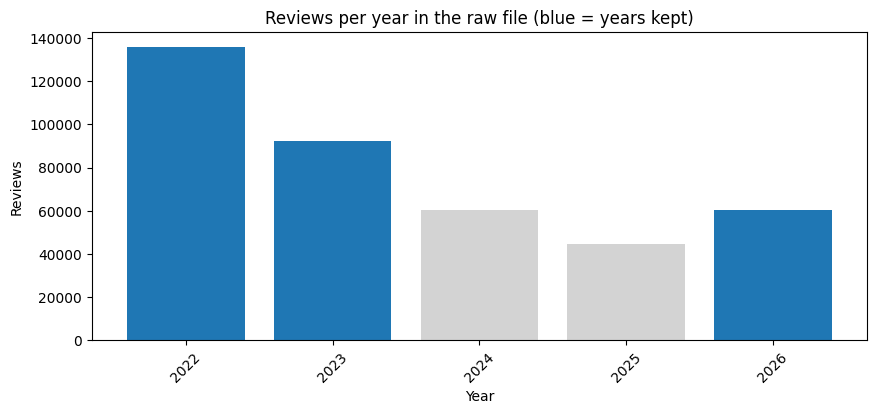

In [9]:
reviews_per_year = df_raw['year'].value_counts().sort_index()
bar_colors = ['tab:blue' if year in YEARS_TO_KEEP else 'lightgrey' for year in reviews_per_year.index]

plt.figure(figsize=(10, 4))
plt.bar(reviews_per_year.index.astype(str), reviews_per_year.values, color=bar_colors)
plt.title('Reviews per year in the raw file (blue = years kept)')
plt.xlabel('Year')
plt.ylabel('Reviews')
plt.xticks(rotation=45)
plt.show()

**What we see:** the file covers several years. The project compares a fixed set of years, so the next step keeps only those.
The last year in the file is not complete (see the last review date above), so for that year averages and shares can be compared, raw counts cannot.

## 2. Keep the project years - ratings set
**Why:** the research question compares the years set by the project. Reviews from other years are not part of the comparison.

We keep only the columns we need: the review id, text, star rating, likes and date. User names, profile pictures and app versions say nothing about consumer value, and user names are personal data we do not need.

In [10]:
columns_to_keep = ['reviewId', 'content', 'score', 'thumbsUpCount', 'at', 'year']
df = df_raw.loc[df_raw['year'].isin(YEARS_TO_KEEP), columns_to_keep].copy()
df['app'] = APP_NAME

log_step('Years kept', df)
df['year'].value_counts().sort_index()

Years kept: 288,475 reviews left


year
2022    136108
2023     92161
2026     60206
Name: count, dtype: int64

**Decision:** the ratings set is saved here, before any text filter.
A star rating is valid whatever the review text says or which language it is written in, so star ratings are always counted on all reviews from the chosen years.

In [11]:
df_ratings = df[['reviewId', 'app', 'year', 'score', 'thumbsUpCount', 'at']].copy()
df_ratings.to_csv(f'{APP_NAME}_reviews_ratings.csv', index=False)
print("Saved ratings set:", len(df_ratings))

Saved ratings set: 288475


In [12]:
ratings_per_year = df_ratings.groupby('year')['score'].agg(['count', 'mean']).round(2)
ratings_per_year.columns = ['reviews', 'average_stars']
ratings_per_year

,reviews,average_stars
year,,
2022,136108,3.71
2023,92161,2.88
2026,60206,3.74


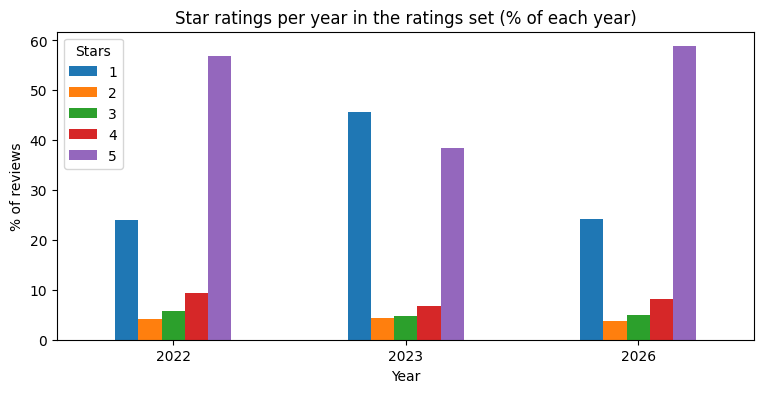

In [13]:
star_share_per_year = pd.crosstab(df_ratings['year'], df_ratings['score'], normalize='index').mul(100).round(1)
star_share_per_year.plot(kind='bar', figsize=(9, 4))
plt.title('Star ratings per year in the ratings set (% of each year)')
plt.xlabel('Year')
plt.ylabel('% of reviews')
plt.xticks(rotation=0)
plt.legend(title='Stars')
plt.show()

## 3. Remove reviews with no text
**Why:** a review without words cannot be read or annotated. Its star rating is already kept in the ratings set.

In [14]:
print("Reviews with no text:", df['content'].isna().sum())

Reviews with no text: 45


In [16]:
df_before = df.copy()
df = df.dropna(subset=['content'])
df['content'] = df['content'].astype(str)
log_step('No missing text', df)

No missing text: 288,430 reviews left


## 4. Clean the text
**Why:** to count words and check the language, the text must be in one simple form.
We work on a copy (`content_clean`). The original `content` stays untouched, so the annotator always reads what the user really wrote.

### 4a. Lowercase
**Why:** "Great" and "great" should count as the same word.

In [17]:
df['content_clean'] = df['content'].str.lower()
df[['content', 'content_clean']].sample(5, random_state=1)

,content,content_clean
284687,Fine,fine
283622,absolutly amazing,absolutly amazing
185104,"जेडसेजवेक्स, सीट एक्स टायट्ट,डी","जेडसेजवेक्स, सीट एक्स टायट्ट,डी"
361377,Osm,osm
167193,💯,💯


### 4b. Remove emojis, symbols and punctuation
**Why:** word counts and the dictionary check work on words only. Emojis, symbols and punctuation are replaced by a space, so words that were glued to them stay separate.
Apostrophes inside words are kept ("can't" is not "can"); quote marks around words are removed.

In [18]:
has_symbols = df['content_clean'].str.contains(r"[^a-z0-9\s']", regex=True)
print(f"Reviews with emojis, symbols or punctuation: {has_symbols.sum():,} ({has_symbols.mean() * 100:.1f}%)")

# most common characters that will be removed
removed_characters = df['content_clean'].str.findall(r"[^a-z0-9\s']").explode().dropna()
removed_characters.value_counts().head(20)

Reviews with emojis, symbols or punctuation: 126,309 (43.8%)


content_clean
.    194098
,     66134
!     48622
?     15092
ا     11586
👍      9332
️      9133
ل      8023
"      7392
❤      6809
-      6722
ي      6447
م      4846
و      4571
)      4277
ر      4232
/      4121
(      4054
👎      3915
ت      3791
Name: count, dtype: int64

In [19]:
df['content_clean'] = df['content_clean'].str.replace(r"[^a-z0-9\s']+", ' ', regex=True)
df['content_clean'] = df['content_clean'].str.replace(r"(?<![a-z0-9])'+|'+(?![a-z0-9])", ' ', regex=True)
df['content_clean'] = df['content_clean'].str.replace(r'\s+', ' ', regex=True).str.strip()

df.loc[has_symbols, ['content', 'content_clean']].sample(min(10, has_symbols.sum()), random_state=1)

,content,content_clean
64205,Terrible to use if you have more then a couple devices I can't even simply cast a show from my phone to my bedroom t...,terrible to use if you have more then a couple devices i can't even simply cast a show from my phone to my bedroom t...
387710,Good app 👍😍😍😍😍😍😍🤩🤩🤩🤩🤩🤩🤩🥳,good app
98172,I just bought an expensive lovely Galaxy Tablet 8+ and can't download shows to the SD card. Research shows it's a co...,i just bought an expensive lovely galaxy tablet 8 and can't download shows to the sd card research shows it's a comm...
127671,Right now we cannot open the app at all. Might want to fix that cause I'm not paying for something that doesn't work.,right now we cannot open the app at all might want to fix that cause i'm not paying for something that doesn't work
117020,Woke pushing agenda in just about every series is garbage and impossible to watch and enjoy while being insulted. No...,woke pushing agenda in just about every series is garbage and impossible to watch and enjoy while being insulted no ...
328781,Great..,great
379733,You guys rock.,you guys rock
232043,I watched Boombayah!,i watched boombayah
316001,Too Good 👍💗,too good
347200,It's so comforting ❤️❤️❤️💓,it's so comforting


### 4c. Keep numbers
**Why:** numbers often carry meaning in these reviews: prices ("15 dollars"), years, "4k", episode numbers. They are kept in `content_clean`, so the annotation can use them.
They are **not** counted as English or non-English in the dictionary check (section 5b), so they do not change whether a review looks English.

In [20]:
number_tokens = df['content_clean'].str.findall(r"\S*\d\S*").explode().dropna()
has_numbers = df['content_clean'].str.contains(r"\d", regex=True)
print(f"Reviews with a number: {has_numbers.sum():,} ({has_numbers.mean() * 100:.1f}%)")
print("Most common number tokens:")
number_tokens.value_counts().head(20)

Reviews with a number: 23,626 (8.2%)
Most common number tokens:


content_clean
2       3965
5       3618
1       3174
3       2351
10      2101
4       1843
7        904
6        802
8        737
0        664
99       613
20       587
9        546
4k       524
100      484
15       435
30       420
12       317
11       273
2022     264
Name: count, dtype: int64

### 4d. Remove reviews with no real word left
**Why:** after cleaning, some reviews are empty or only single letters or numbers (they were only emojis, numbers or symbols). They have nothing to read or annotate.
A review must contain at least one word of two or more letters.

In [21]:
df_before = df.copy()
df = df[df['content_clean'].str.contains(r'[a-z]{2,}', regex=True)].copy()
log_step('Has a real word', df)
show_removed(df_before, df)

Has a real word: 278,908 reviews left
Removed: 9,522 reviews (3.3%)


,content,score,year
326691,💢,5,2022
112468,😤,1,2022
213074,👍,5,2026
83310,نجمة واحدة يا ولاد الو س خة عشان تعرفوا تشوهوا تاريخنا زي الناس قرف يقرفكم والله ما حطيت النجمة غير عشان اعرف اكتب ك...,1,2023
203818,🔥♦,4,2022
77332,يا ولاد الوسخة عايزين تزيفو التاريخ,1,2023
82238,لا تيجي علي مصر لانو دايما الي قبلك خسر فا متحولش ي ليفه,1,2023
325346,🤐😋😣🤐😂😋🤐🤐🤐🤐,5,2022
330831,P 9oòe9⁹e 2,5,2022
168773,Хотілося б більше української локалізації контенту,3,2022


## 5. Keep English reviews
**Why:** the annotation and the word checks are in English. Two checks are used:
- **5a. Language detector:** removes reviews written in another language.
- **5b. Dictionary check:** removes gibberish and other-language text the detector missed.

### 5a. Language detector
The language is detected on the **original** text, because punctuation and full sentences help the detector.

In [22]:
def detect_language(text):
    try:
        result = detect(text.replace('\n', ' '), model='auto', k=1)
        return result[0]['lang']
    except Exception:
        return 'unknown'

df['language'] = df['content'].apply(detect_language)
language_counts = df['language'].value_counts()
print(f"Detected as English: {(df['language'] == 'en').sum():,} ({(df['language'] == 'en').mean() * 100:.1f}%)")
language_counts.head(15)

Detected as English: 259,028 (92.9%)


language
en     259028
it       2417
de       2374
fr       2076
es       2031
nl       1101
pt        936
id        899
sv        649
ru        645
pl        520
ceb       439
tl        427
ja        414
hu        408
Name: count, dtype: int64

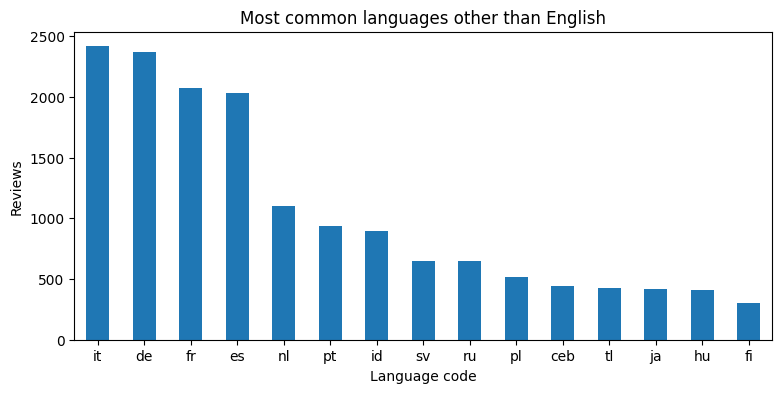

In [23]:
plt.figure(figsize=(9, 4))
language_counts.drop('en', errors='ignore').head(15).plot(kind='bar')
plt.title('Most common languages other than English')
plt.xlabel('Language code')
plt.ylabel('Reviews')
plt.xticks(rotation=0)
plt.show()

In [24]:
# examples of reviews detected as another language
not_english = df[df['language'] != 'en']
not_english_words = not_english['content_clean'].str.split().str.len()

print(f"Non-English reviews with fewer than 3 words: {(not_english_words < 3).sum():,} of {len(not_english):,}")
not_english.loc[not_english_words < 3, ['content', 'language']].sample(min(15, (not_english_words < 3).sum()), random_state=1)

Non-English reviews with fewer than 3 words: 13,583 of 19,880


,content,language
81098,👎 bad ْ,it
380320,Ok,it
389819,Love Netflix,fr
376594,Okk,no
214515,5 star,it
220818,excelente experiencia,es
280670,No adds,new
392765,Ok,it
359777,Love netflix!!,de
116327,Cb kau,id


In [25]:
print(f"Non-English reviews with 3 or more words: {(not_english_words >= 3).sum():,} of {len(not_english):,}")
not_english.loc[not_english_words >= 3, ['content', 'language']].sample(min(15, (not_english_words >= 3).sum()), random_state=1)

Non-English reviews with 3 or more words: 6,297 of 19,880


,content,language
334608,try ku muna manuod paanu ba gawen.,cy
333578,Ver y ver gud,es
197015,i love it thats all im saying,de
206774,I love it❤️❤️❤️,sv
148151,"Kenapa text nya putih, gak bisa di baca donk kl terang layar nya",id
110584,Ci dovrebbe essere la possibilità di selezionare i film per lingua. Principio di funzionamento completamente senza s...,it
131152,Bad so bad,de
376957,Hurra för Netflix! 🙂,sv
335333,Ho bhai maja a Gaya,pl
205567,Filme pentru toate gusturile.,ro


In [26]:
df_before = df.copy()
df = df[df['language'] == 'en'].copy()
log_step('English (detector)', df)
show_removed(df_before, df)

English (detector): 259,028 reviews left
Removed: 19,880 reviews (7.1%)


,content,score,year
211007,gooooooood,5,2026
129720,Very bad,1,2022
115,"Propagandas, que coisa nojenta",1,2026
350441,Pro👑,5,2022
85496,Not convenient,1,2023
323705,Mast ha ya app,5,2022
376117,Ok,5,2022
10463,no sbr?,1,2026
344248,Gay ppl,5,2022
323786,Anime,5,2022


### 5b. Dictionary check
**Why:** some reviews pass the detector but are not readable English: gibberish ("eww ee ww"), names, or other languages written in Latin letters.
For each review we compute the share of its words that are English words. Numbers are left out of this count. A review is kept if at least `MIN_REAL_WORD_RATIO` of its words are real words.

**A strict dictionary is not enough.** The NLTK word list misses many normal forms ("crashing", "discontinued") and app words ("netflix", "subscription"). So a word also counts as real if:
- it contains an apostrophe (contractions like "don't", "it's");
- it is an app or streaming word from our list;
- it is a dictionary word plus a common ending (-s, -es, -d, -ed, -ing, -ly, -er), also with a doubled letter ("stopped" → "stop").

In [27]:
nltk.download('words', quiet=True)
english_vocab = set(w.lower() for w in words.words())
app_words = {'netflix', 'amazon', 'prime', 'app', 'apps', 'tv','ads',  'adverts', 'advt',
             'subscription', 'subscriptions', 'streaming', 'login', 'logout', 'wifi',
             'chromecast', 'android', 'iphone', 'ipad', 'hd', 'overpriced', 'cancelled', 'canceled'}
english_vocab = english_vocab | app_words

def is_dictionary_word(word):
    return word in english_vocab

def is_real_word(word):
    if "'" in word or word in english_vocab:
        return True
    for ending in ['s', 'es', 'd', 'ed', 'ing', 'ly', 'er']:
        if word.endswith(ending):
            base = word[:-len(ending)]
            if len(base) >= 3 and (base in english_vocab or base[:-1] in english_vocab):
                return True
    return False

def real_word_ratio(text, word_check):
    tokens = [w for w in text.split() if not any(ch.isdigit() for ch in w)]   # numbers are not counted
    if len(tokens) == 0:
        return 0
    return sum(1 for w in tokens if word_check(w)) / len(tokens)

df['strict_ratio'] = df['content_clean'].apply(lambda text: real_word_ratio(text, is_dictionary_word))
df['real_word_ratio'] = df['content_clean'].apply(lambda text: real_word_ratio(text, is_real_word))
df['real_word_ratio'].describe()

count    259028.000000
mean          0.944828
std           0.148511
min           0.000000
25%           0.958333
50%           1.000000
75%           1.000000
max           1.000000
Name: real_word_ratio, dtype: float64

**Choosing the threshold:** first we look at the distribution and at what each candidate threshold would remove, then we choose.

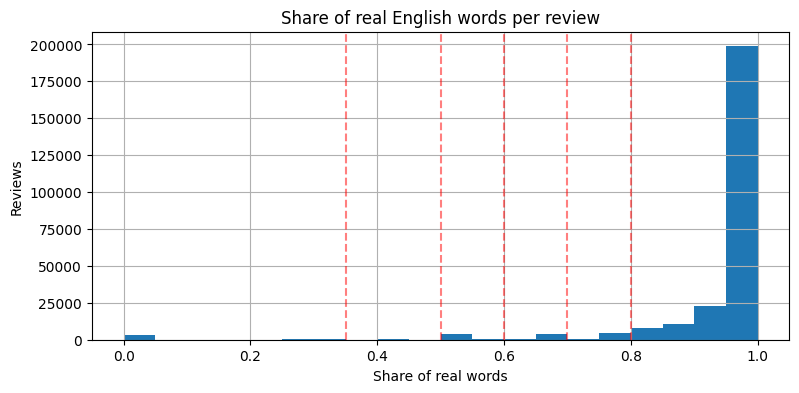

In [30]:
CANDIDATES = [0.35, 0.5, 0.6, 0.7, 0.8]

plt.figure(figsize=(9, 4))
df['real_word_ratio'].hist(bins=20)
for threshold in CANDIDATES:
    plt.axvline(threshold, linestyle='--', color='red', alpha=0.5)
plt.title('Share of real English words per review')
plt.xlabel('Share of real words')
plt.ylabel('Reviews')
plt.show()

In [31]:
for threshold in CANDIDATES:
    removed = (df['real_word_ratio'] < threshold).sum()
    print(f"Threshold {threshold}: removes {removed:,} reviews ({removed / len(df) * 100:.1f}%)")

Threshold 0.35: removes 4,293 reviews (1.7%)
Threshold 0.5: removes 4,793 reviews (1.9%)
Threshold 0.6: removes 8,939 reviews (3.5%)
Threshold 0.7: removes 13,337 reviews (5.1%)
Threshold 0.8: removes 18,629 reviews (7.2%)


**Reading examples in each band:** which reviews would each threshold remove?

In [32]:
bands = [(0, 0.35), (0.35, 0.5), (0.5, 0.6), (0.6, 0.7), (0.7, 0.8), (0.8, 1.0)]
for low, high in bands:
    band = df[(df['real_word_ratio'] >= low) & (df['real_word_ratio'] < high)]
    print(f"--- share of real words {low}–{high}: {len(band):,} reviews ---")
    print(band['content'].sample(min(10, len(band)), random_state=1).to_string(index=False))
    print()

--- share of real words 0–0.35: 4,293 reviews ---
                                             Prem
                                         Download
                                              Osm
                                              Okz
                                         Woooooow
Napakabobo ng developer nito lagi ng blacksccreen
                                             Naic
                               Shelembe nhlamhlaz
                          NARUTUKE THAKTKI BAIOOO
                                Madarcod tor nani

--- share of real words 0.35–0.5: 500 reviews ---
                                         Super. Zeeex XD xx too I'm, by ZZ, ZZ ZZ ZZ z ZZ ZZ f see see a ss ,Tdnfcebe eç
1. Jai Ho 2014, 2. Kick 2014, 3. Bajrangi Bhaijaan 2015, 4. Tubelight 2017, 5. Race 3 2018, 6. Bharat 2019, 7. Dabang...
    ap ki app pr new launch movie nhi aati hai soo plese es chij ko tek kre nhi to hum aage se es app ka primem nhi legi
                                    

**Words not recognised in each band:** helps to see whether the removed reviews are really not English, or only use words missing from the dictionary (which could be added to `app_words`).

In [33]:
for low, high in bands[:-1]:
    band = df[(df['real_word_ratio'] >= low) & (df['real_word_ratio'] < high)]
    unknown = band['content_clean'].str.split().explode()
    unknown = unknown[~unknown.str.contains(r'\d') & ~unknown.apply(is_real_word)]
    print(f"--- {low}–{high}: most common unrecognised words ---")
    print(unknown.value_counts().head(15).to_dict())
    print()

--- 0–0.35: most common unrecognised words ---
{'hai': 156, 'osm': 114, 'okay': 58, 'excelent': 49, 'aap': 48, 'bakwas': 48, 'wonyoung': 42, 'nic': 40, 'download': 36, 'nhi': 35, 'greatest': 35, 'bhai': 33, 'ki': 33, 'bloatware': 28, 'yay': 28}

--- 0.35–0.5: most common unrecognised words ---
{'hai': 293, 'bhi': 88, 'nhi': 77, 'ke': 57, 'ki': 52, 'nahi': 51, 'nahin': 44, 'aur': 42, 'raha': 40, 'ii': 39, 'kar': 38, 'aap': 37, 'download': 31, 'liye': 29, 'ek': 28}

--- 0.5–0.6: most common unrecognised words ---
{'hai': 239, 'aap': 177, 'download': 122, 'okay': 100, 'sbr': 81, 'nhi': 73, 'verry': 69, 'bhi': 66, 'uninstall': 57, 'ke': 53, 'nahi': 53, 'ki': 51, 'soo': 40, 'lol': 38, 'kar': 38}

--- 0.6–0.7: most common unrecognised words ---
{'download': 192, 'sbr': 145, 'hai': 120, 'has': 119, 'ott': 98, 'pls': 84, 'aap': 77, 'uninstall': 71, 'plz': 56, 'naruto': 50, 'soo': 47, 'ui': 46, 'nhi': 46, 'bhi': 46, 'egyption': 41}

--- 0.7–0.8: most common unrecognised words ---
{'download': 3

**Strict vs loosened dictionary:** these reviews would be removed with the strict word list but are kept with the loosened one.

In [34]:
brought_back = df[(df['strict_ratio'] < MIN_REAL_WORD_RATIO) & (df['real_word_ratio'] >= MIN_REAL_WORD_RATIO)]
print("Reviews kept thanks to the loosened dictionary:", len(brought_back))
brought_back[['content', 'content_clean']].sample(min(15, len(brought_back)), random_state=1)

Reviews kept thanks to the loosened dictionary: 8602


,content,content_clean
87870,Supports the afrocentric movement,supports the afrocentric movement
283525,It's good,it's good
153088,5 stars,5 stars
195873,It's okay for me,it's okay for me
304281,"Great,, movies",great movies
128267,It's not playing from 2 weeks some error is occurring,it's not playing from 2 weeks some error is occurring
79052,FAKING HISTORY,faking history
168322,It's okay not good movies on here,it's okay not good movies on here
350697,Great movies.,great movies
358376,Is life changing of movies and downloads.,is life changing of movies and downloads


**Decision: MIN_REAL_WORD_RATIO = 0.6.**
- Below 0.6 the examples are mostly gibberish, names or other languages in Latin letters.
- From 0.6 up, the reviews are readable English, sometimes with a few slang or misspelled words.
- A higher threshold (0.7–0.8) would start removing readable reviews with typos or slang.

In [35]:
df_before = df.copy()
df = df[df['real_word_ratio'] >= MIN_REAL_WORD_RATIO].copy()
df = df.drop(columns=['strict_ratio', 'real_word_ratio', 'language'])
log_step('Real English words', df)
show_removed(df_before, df, n=20)

Real English words: 250,089 reviews left
Removed: 8,939 reviews (3.5%)


,content,score,year
7686,uninstall karo sabhi isko 👎,1,2026
219851,osham,5,2026
162219,2a..2nd l6ĺml Mm O. O OAugulsll.lt .oomo,3,2023
302926,Good appxxxxx💢💯,5,2023
212794,okay,5,2026
97658,It's okay,1,2023
298178,Gooooddd,5,2023
310058,Greatest ever,5,2023
130012,JEEVAN,1,2022
377342,botty,5,2022


## 6. Save the full clean set
This set keeps every clean English review. It is used for the text analysis, so it is not reduced any further.

In [36]:
df['word_count'] = df['content_clean'].str.split().str.len()
df['text_repeats'] = df.groupby('content_clean')['reviewId'].transform('count')   # how often the same clean text appears

df_clean_full = df.copy()
df_clean_full.to_csv(f'{APP_NAME}_reviews_clean_full.csv', index=False)
print("Saved full clean set:", len(df_clean_full))

Saved full clean set: 250089


**Check: does the text cleaning change the star ratings?** If the averages per year are close, removing empty, non-English and gibberish reviews does not bias the ratings.

In [37]:
rating_check = pd.DataFrame({
    'ratings_set': df_ratings.groupby('year')['score'].mean(),
    'clean_text_set': df_clean_full.groupby('year')['score'].mean()}).round(2)
rating_check['difference'] = rating_check['clean_text_set'] - rating_check['ratings_set']
rating_check

,ratings_set,clean_text_set,difference
year,,,
2022,3.71,3.70,-0.01
2023,2.88,2.87,-0.01
2026,3.74,3.71,-0.03


## 7. Repeated texts
**Why check:** many identical reviews could be spam or a coordinated campaign rather than individual opinions. We look at them on the full clean set, **before** the length cut, so short repeated phrases and campaigns are both visible.
Common short phrases ("i love this app") repeat naturally. A campaign looks like one specific message, often off-topic, many times, with all 1 or all 5 stars.

**Decision:** repeated texts are kept in the clean set, because they are real reviews. The column `text_repeats` (how many times the same clean text appears) identifies them, so they can be excluded later in the analysis.

In [38]:
repeated = (df_clean_full[df_clean_full['text_repeats'] >= 5]
            .groupby('content_clean')
            .agg(times=('reviewId', 'count'), words=('word_count', 'first'), average_stars=('score', 'mean'),
                 first_year=('year', 'min'), last_year=('year', 'max'))
            .sort_values('times', ascending=False))
repeated['average_stars'] = repeated['average_stars'].round(2)
print("Texts repeated 5 or more times:", len(repeated))
print("Reviews involved:", repeated['times'].sum())
repeated.head(25)

Texts repeated 5 or more times: 1533
Reviews involved: 80793


,times,words,average_stars,first_year,last_year
content_clean,,,,,
good,14870,1,4.62,2022,2026
nice,4812,1,4.66,2022,2026
great,3749,1,4.85,2022,2026
excellent,2966,1,4.89,2022,2026
awesome,2795,1,4.87,2022,2026
very good,2446,2,4.78,2022,2026
love it,2299,2,4.90,2022,2026
amazing,1621,1,4.88,2022,2026
best,1449,1,4.82,2022,2026


**Long repeated texts:** a long text written many times is unlikely to be a coincidence; this is where campaigns show up.

In [40]:
repeated[repeated['words'] >= MIN_WORDS]

,times,words,average_stars,first_year,last_year
content_clean,,,,,


**Are short reviews more repeated?** Share of reviews whose exact text appears more than once, by length.

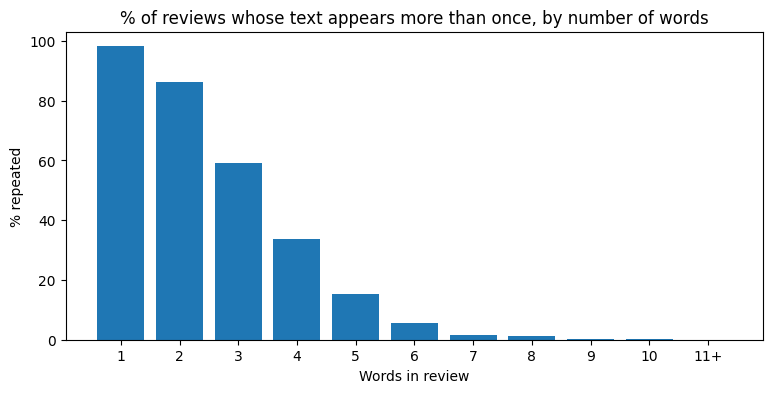

words_group
1      98.2
2      86.3
3      59.1
4      33.8
5      15.3
6       5.5
7       1.7
8       1.1
9       0.2
10      0.3
11+     0.0
Name: text_repeats, dtype: float64

In [41]:
df_clean_full['words_group'] = df_clean_full['word_count'].clip(upper=11)
group_labels = {i: str(i) for i in range(1, 11)}
group_labels[11] = '11+'

repeat_by_length = (df_clean_full['text_repeats'] > 1).groupby(df_clean_full['words_group']).mean().mul(100).round(1)
repeat_by_length.index = repeat_by_length.index.map(group_labels)

plt.figure(figsize=(9, 4))
plt.bar(repeat_by_length.index, repeat_by_length.values)
plt.title('% of reviews whose text appears more than once, by number of words')
plt.xlabel('Words in review')
plt.ylabel('% repeated')
plt.show()
repeat_by_length

## 8. Review length - annotation set
**Why:** the annotation looks for the *reasons* behind satisfaction (price, ads, content, technical problems). The star rating already tells us *how* satisfied a user is.
Very short reviews ("good", "love it") show a feeling but rarely a reason. We look at the data to decide how many words a review needs.

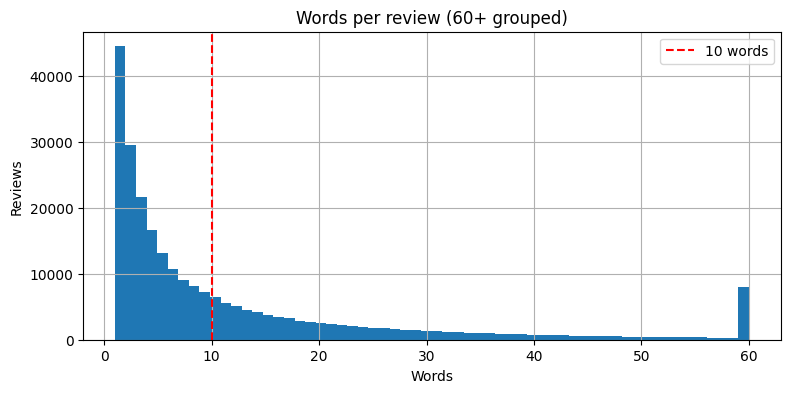

In [42]:
plt.figure(figsize=(9, 4))
df_clean_full['word_count'].clip(upper=60).hist(bins=60)
plt.axvline(MIN_WORDS, color='red', linestyle='--', label=f'{MIN_WORDS} words')
plt.title('Words per review (60+ grouped)')
plt.xlabel('Words')
plt.ylabel('Reviews')
plt.legend()
plt.show()

In [43]:
length_table = df_clean_full.groupby('words_group').agg(
    reviews=('reviewId', 'count'),
    average_stars=('score', 'mean'))
length_table['% of reviews'] = (length_table['reviews'] / len(df_clean_full) * 100).round(1)
length_table['average_stars'] = length_table['average_stars'].round(2)
length_table.index = length_table.index.map(group_labels)
length_table

,reviews,average_stars,% of reviews
words_group,,,
1,44445,4.56,17.8
2,29577,4.15,11.8
3,21679,3.58,8.7
4,16637,3.57,6.7
5,13097,3.39,5.2
6,10763,3.30,4.3
7,9119,3.24,3.6
8,8095,3.23,3.2
9,7181,3.19,2.9


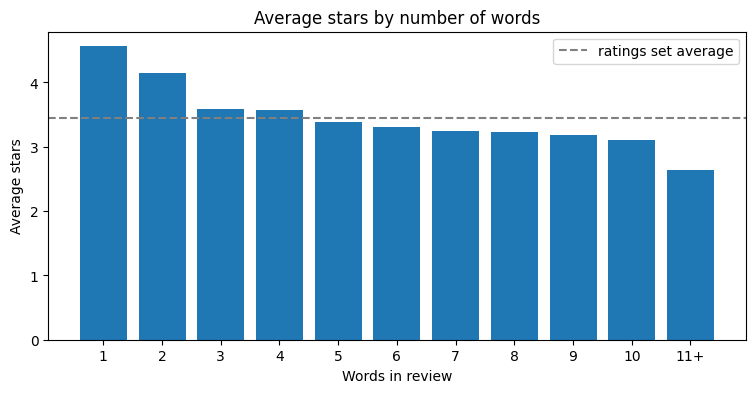

In [44]:
plt.figure(figsize=(9, 4))
plt.bar(length_table.index, length_table['average_stars'])
plt.axhline(df_ratings['score'].mean(), color='grey', linestyle='--', label='ratings set average')
plt.title('Average stars by number of words')
plt.xlabel('Words in review')
plt.ylabel('Average stars')
plt.legend()
plt.show()

**Do short reviews talk about value?** We count reviews that mention a price, ads, subscription or content word, by length.

In [45]:
value_words = (r"\b(price|prices|expensive|cheap|money|cost|costs|pay|paid|paying|worth|subscription|"
               r"rent|rental|ads|ad|advt|advertisement|advertisements|free|fee|charge|charged|membership|content|available)\b")
df_clean_full['mentions_value'] = df_clean_full['content_clean'].str.contains(value_words, regex=True)

value_table = df_clean_full.groupby('words_group')['mentions_value'].agg(['mean', 'sum'])
value_table.columns = ['% mentioning value', 'reviews mentioning value']
value_table['% mentioning value'] = (value_table['% mentioning value'] * 100).round(1)
value_table.index = value_table.index.map(group_labels)
value_table

C:\Users\elesa\AppData\Local\Temp\ipykernel_23640\3853407355.py:3: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df_clean_full['mentions_value'] = df_clean_full['content_clean'].str.contains(value_words, regex=True)


,% mentioning value,reviews mentioning value
words_group,,
1,0.3,124
2,2.2,651
3,3.1,672
4,5.0,832
5,6.5,852
6,8.2,887
7,8.4,763
8,9.7,782
9,10.8,772


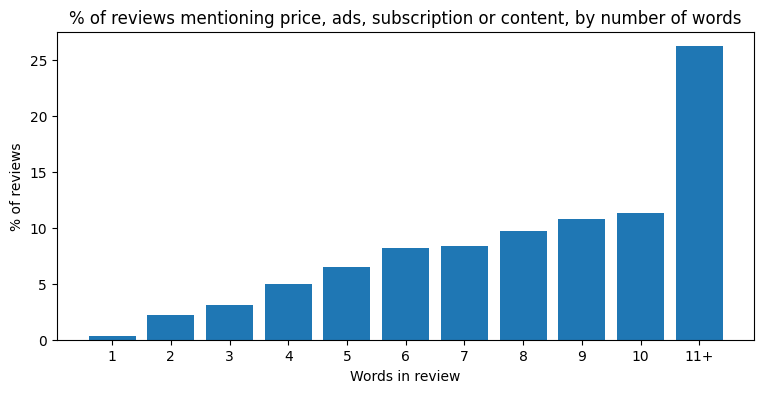

In [46]:
plt.figure(figsize=(9, 4))
plt.bar(value_table.index, value_table['% mentioning value'])
plt.title('% of reviews mentioning price, ads, subscription or content, by number of words')
plt.xlabel('Words in review')
plt.ylabel('% of reviews')
plt.show()

**Reading examples:** do reviews of this length give a reason?

In [47]:
for n_words in [3, 5, 8, 10, 15]:
    print(f"--- {n_words} words ---")
    same_length = df_clean_full[df_clean_full['word_count'] == n_words]['content']
    print(same_length.sample(min(10, len(same_length)), random_state=1).to_string(index=False))
    print()

--- 3 words ---
    Its just awesome
           I love It
  Not interested app
   Need more seasons
           I love it
 Egypt for Egyptians
Netflix is !awesome!
        It's so good
       Good and free
      So many glichs

--- 5 words ---
          The best app for movies
      why cant use different wifi
                 It is fine to me
Screw your password sharing fees.
     I cant share with family?...
    Easy to follow and understand
 THIS APP IS TRASH 🗑️🗑️ TRASH 🤮🤢👎
       A life and sanity saver...
              Am in love with app
    it's say's Netflix has stop!!

--- 8 words ---
     Movies apparently available then not on the platform
                       It is nice and easy to watch films
                    I really like the way you look nice ☺
                 Wonderful to have this app on your phone
               Grgeat app for entertainment so on in 2026
                          i love it so much its super fun
                         I do not have a purpose wit

**Comparing cuts:** what each minimum length keeps, and how it changes the stars and the years.

In [48]:
cut_rows = []
for min_words in [3, 5, 8, 10, 15]:
    kept = df_clean_full[df_clean_full['word_count'] >= min_words]
    row = {'minimum words': min_words,
           'reviews kept': len(kept),
           '% kept': round(len(kept) / len(df_clean_full) * 100, 1),
           'average stars': round(kept['score'].mean(), 2),
           '% mentioning value': round(kept['mentions_value'].mean() * 100, 1)}
    for year in YEARS_TO_KEEP:
        row[f'{year} kept'] = (kept['year'] == year).sum()
    cut_rows.append(row)

cut_table = pd.DataFrame(cut_rows)
cut_table

,minimum words,reviews kept,% kept,average stars,% mentioning value,2022 kept,2023 kept,2026 kept
0,3,176067,70.4,3.04,15.9,77479,59005,39583
1,5,137751,55.1,2.89,19.2,60103,45665,31983
2,8,104772,41.9,2.75,22.9,45311,34992,24469
3,10,89496,35.8,2.67,25.1,38500,30057,20939
4,15,63658,25.5,2.52,29.8,26909,21659,15090


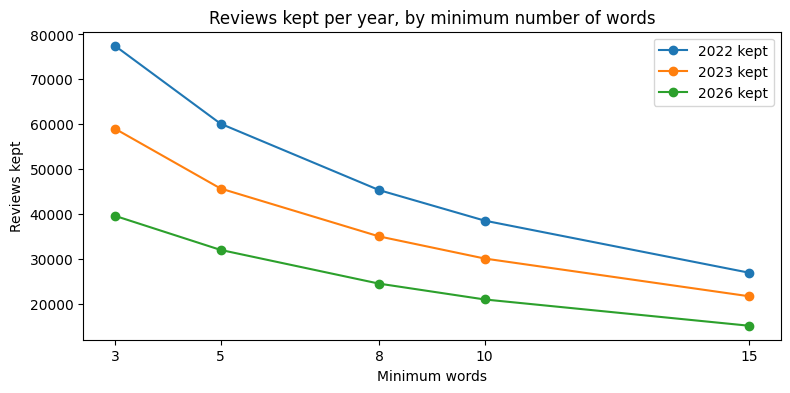

In [49]:
year_columns = [f'{year} kept' for year in YEARS_TO_KEEP]
cut_table.set_index('minimum words')[year_columns].plot(marker='o', figsize=(9, 4))
plt.title('Reviews kept per year, by minimum number of words')
plt.xlabel('Minimum words')
plt.ylabel('Reviews kept')
plt.xticks(cut_table['minimum words'])
plt.show()

**Decision: 10 words or more.**
- Reviews under 10 words are mostly a feeling ("love it", "worst app ever") and rarely say *why*; the share of reviews mentioning price, ads or content grows with length.
- Short reviews are also much more often repeated word for word (section 7), so they add little new information.
- With 10+ words every year still has far more reviews than the sample needs (section 10).
- Any minimum length makes the set more negative, because longer reviews are more often complaints. This is why star ratings are always taken from the ratings set, not from the annotation set.
- Likes are not used: most reviews have none, and likes depend on how long a review has been online.

In [50]:
df_before = df_clean_full.copy()
df_annotate = df_clean_full[df_clean_full['word_count'] >= MIN_WORDS].copy()
log_step(f'{MIN_WORDS}+ words', df_annotate)
show_removed(df_before, df_annotate, n=20)

10+ words: 89,496 reviews left
Removed: 160,593 reviews (64.2%)


,content,score,year
85808,ancient Egyptians were not black,1,2023
193240,Great experience,4,2022
317662,Great,5,2022
109662,very poor service,1,2022
188884,Awesome thanks,4,2023
66180,I. Now love it,1,2023
205673,the best show ive ever watched (the body),5,2026
202272,Very helpful,4,2022
335250,Good for knowledge,5,2022
389600,It works really good,5,2022


## 9. Remove duplicates - annotation set
**Why:** the same text gets the same annotation, so annotating it more than once only costs time. Each text is kept once; `text_repeats` says how many reviews it stands for.

! Remember to redistribute the labels back to every review with the same `content_clean` when needed.

In [51]:
df_annotate_unique = df_annotate.drop_duplicates(subset=['content_clean']).copy()
log_step('No duplicates', df_annotate_unique)
show_removed(df_annotate, df_annotate_unique)

No duplicates: 89,474 reviews left
Removed: 22 reviews (0.0%)


,content,score,year
235941,"First off, I really enjoy Netflix. It has a wide variety of movies and series to choose from, so there’s always some...",5,2026
221368,"Best Streaming Service! ⭐️⭐️⭐️⭐️⭐️Netflix offers an incredible selection of movies, TV shows, and original series. T...",5,2026
76184,Serious issue with Netflix last 3 days. After latest update my app gets stuck whenever I open it. I can only see a s...,1,2023
161012,Right now whenever we are going to download GTA san andreas Netflix from Play Store it is showing your device is not...,3,2023
235333,"Netflix is the one of the best movie apps for me. I can watch every kind of movies, TV shows, and WebSeries on it. N...",5,2026
203904,Netflix is the leading subscription service for watching TV episodes and films. Looking for the most talked-about TV...,4,2022
92608,"Netflix has chosen to be every egyptian's enemy by faking our history,this is absolutely nonsense",1,2023
91988,Netflix is falsifying history and support backwashing ancient Egyptian history,1,2023
70397,Netflix is falsifying history and supports blackwashing Ancient Egyptian history.,1,2023
225271,"My experience with Netflix has been pretty smooth. It's a lightweight version of the main app, and I like how it use...",5,2026


In [52]:
annotate_cols = ['reviewId', 'app', 'year', 'score', 'thumbsUpCount', 'word_count', 'text_repeats', 'content', 'content_clean']
df_annotate_unique[annotate_cols].to_csv(f'{APP_NAME}_reviews_to_annotate.csv', index=False)
print("Saved annotation set:", len(df_annotate_unique))
df_annotate_unique['year'].value_counts().sort_index()

Saved annotation set: 89474


year
2022    38496
2023    30045
2026    20933
Name: count, dtype: int64

## 10. Sample for the automatic annotation
**Why:** annotating the whole annotation set would take many hours, and the comparison between years only needs a large enough sample of each year.
We take **5,000 reviews per app (10,000 in total)**, split **equally between the years**. With the same number of reviews, every year is measured with the same precision (about ±2.4 percentage points with ~1,667 reviews), so differences between years are not caused by different sample sizes.

The reviews we annotated by hand are **left out**: they are the test set used to check the quality of the automatic annotation, so they must not be in the sample the model labels.

In [55]:
per_year_hand = HAND_SIZE // len(YEARS_TO_KEEP)
extra_hand = HAND_SIZE % len(YEARS_TO_KEEP)

hand_parts = []
for i, year in enumerate(YEARS_TO_KEEP):
    n = per_year_hand + (1 if i < extra_hand else 0)
    year_pool = df_annotate_unique[df_annotate_unique['year'] == year]
    hand_parts.append(year_pool.sample(min(n, len(year_pool)), random_state=RANDOM_SEED + 1))

hand = pd.concat(hand_parts).sample(frac=1, random_state=RANDOM_SEED)   # shuffle, so years are mixed
hand = pd.DataFrame({
    'sample_id': range(1, len(hand) + 1),
    'reviewId': hand['reviewId'].values,
    'Service': APP_NAME,
    'Year': hand['year'].values,
    'Stars': hand['score'].values,
    'Words': hand['word_count'].values,
    'Review text': hand['content'].values,
    'content_clean': hand['content_clean'].values,
    'Your label': '',
    'Comment': ''})
hand.to_excel(HAND_FILE, index=False)
print(f"Created {HAND_FILE}: {len(hand)} reviews to annotate by hand")
print(hand['Year'].value_counts().sort_index())

is_hand_labelled = df_annotate_unique['reviewId'].isin(hand['reviewId'])
print(f"Left out of the sample: {is_hand_labelled.sum()}")
sample_pool = df_annotate_unique[~is_hand_labelled]

Created netflix_human_annotation.xlsx: 50 reviews to annotate by hand
Year
2022    17
2023    17
2026    16
Name: count, dtype: int64
Left out of the sample: 50


In [56]:
per_year = SAMPLE_SIZE // len(YEARS_TO_KEEP)
extra = SAMPLE_SIZE % len(YEARS_TO_KEEP)      # left-over reviews go to the first years, so the total is exact

samples = []
for i, year in enumerate(YEARS_TO_KEEP):
    n = per_year + (1 if i < extra else 0)
    year_pool = sample_pool[sample_pool['year'] == year]
    if len(year_pool) < n:
        print(f"! {year}: only {len(year_pool):,} reviews available, all are taken")
        n = len(year_pool)
    samples.append(year_pool.sample(n, random_state=RANDOM_SEED))

df_sample = pd.concat(samples)
print(f"Sample: {len(df_sample):,} reviews")
df_sample['year'].value_counts().sort_index()

Sample: 5,000 reviews


year
2022    1667
2023    1667
2026    1666
Name: count, dtype: int64

**Check: is the sample like the annotation set it comes from?** Within each year, the stars and the length should be close, because the sample is random.

In [57]:
sample_check = pd.DataFrame({
    'set_stars': df_annotate_unique.groupby('year')['score'].mean(),
    'sample_stars': df_sample.groupby('year')['score'].mean(),
    'set_median_words': df_annotate_unique.groupby('year')['word_count'].median(),
    'sample_median_words': df_sample.groupby('year')['word_count'].median()}).round(2)
sample_check

,set_stars,sample_stars,set_median_words,sample_median_words
year,,,,
2022,2.84,2.87,20.0,20.0
2023,2.19,2.11,21.0,21.0
2026,3.05,2.99,21.0,22.0


In [58]:
df_sample[annotate_cols].to_csv(f'{APP_NAME}_sample_to_annotate.csv', index=False)
print("Saved sample:", len(df_sample))

Saved sample: 5000


## 11. Summary
### Reviews left after each step

In [59]:
log = pd.DataFrame(cleaning_log, columns=['step', 'rows_left'])
log['removed'] = log['rows_left'].shift(1) - log['rows_left']
log['removed_%_of_previous'] = (log['removed'] / log['rows_left'].shift(1) * 100).round(1)
print("Original file:", len(df_raw))
print(log.to_string(index=False))

Original file: 393079
              step  rows_left  removed  removed_%_of_previous
        Years kept     288475      NaN                    NaN
   No missing text     288430     45.0                    0.0
   No missing text     288430      0.0                    0.0
   Has a real word     278908   9522.0                    3.3
English (detector)     259028  19880.0                    7.1
Real English words     250089   8939.0                    3.5
         10+ words      89496 160593.0                   64.2
     No duplicates      89474     22.0                    0.0


In [60]:
year_table = pd.concat(year_log, axis=1)
year_table

,Years kept,No missing text,No missing text,Has a real word,English (detector),Real English words,10+ words,No duplicates
year,,,,,,,,
2022,136108,136081,136081,131749,121524,116928,38500,38496
2023,92161,92145,92145,88300,81923,79028,30057,30045
2026,60206,60204,60204,58859,55581,54133,20939,20933


In [61]:
# % of each year's reviews still left after each step
year_pct = (year_table.div(year_table['Years kept'], axis=0) * 100).round(1)
year_pct

,Years kept,No missing text,No missing text,Has a real word,English (detector),Real English words,10+ words,No duplicates
year,,,,,,,,
2022,100.0,100.0,100.0,96.8,89.3,85.9,28.3,28.3
2023,100.0,100.0,100.0,95.8,88.9,85.7,32.6,32.6
2026,100.0,100.0,100.0,97.8,92.3,89.9,34.8,34.8


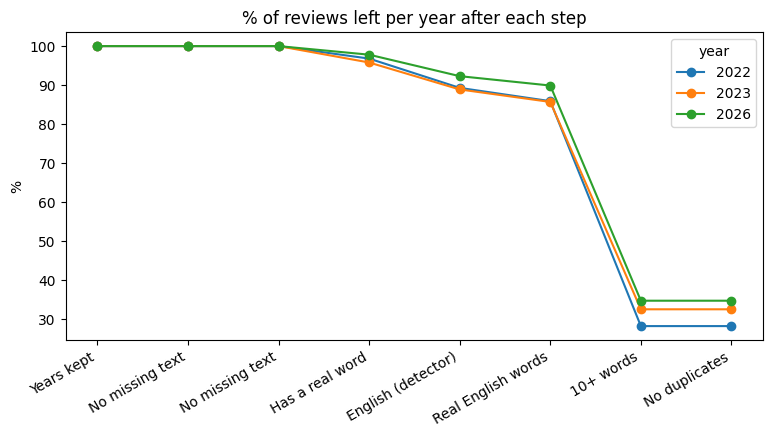

In [62]:
year_pct.T.plot(marker='o', figsize=(9, 4))
plt.title('% of reviews left per year after each step')
plt.ylabel('%')
plt.xticks(range(len(year_pct.columns)), year_pct.columns, rotation=30, ha='right')
plt.show()

### Star ratings in the sets
The ratings set and the clean text set should be close. The annotation set is expected to be more negative, because it keeps longer reviews. The sample should be close to the annotation set.

In [63]:
mean_rating_all = pd.DataFrame({
    'ratings_set': df_ratings.groupby('year')['score'].mean(),
    'clean_text_set': df_clean_full.groupby('year')['score'].mean(),
    'annotation_set': df_annotate_unique.groupby('year')['score'].mean(),
    'sample': df_sample.groupby('year')['score'].mean()}).round(2)
mean_rating_all

,ratings_set,clean_text_set,annotation_set,sample
year,,,,
2022,3.71,3.70,2.84,2.87
2023,2.88,2.87,2.19,2.11
2026,3.74,3.71,3.05,2.99


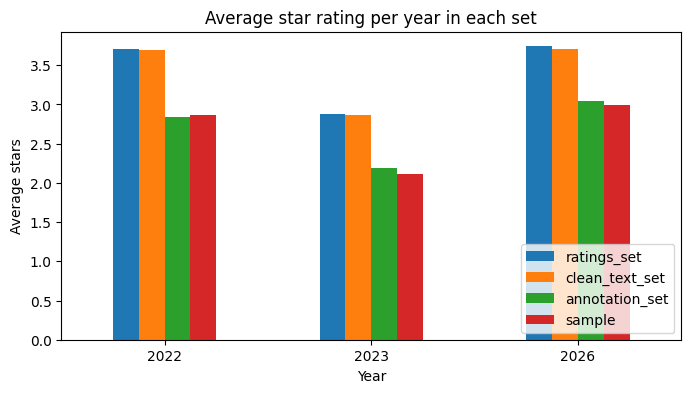

In [64]:
mean_rating_all.plot(kind='bar', figsize=(8, 4))
plt.title('Average star rating per year in each set')
plt.xlabel('Year')
plt.ylabel('Average stars')
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.show()

In [65]:
star_pct_all = pd.DataFrame({
    'ratings_set': df_ratings['score'].value_counts(normalize=True),
    'clean_text_set': df_clean_full['score'].value_counts(normalize=True),
    'annotation_set': df_annotate_unique['score'].value_counts(normalize=True),
    'sample': df_sample['score'].value_counts(normalize=True)}).sort_index().mul(100).round(1)
star_pct_all

,ratings_set,clean_text_set,annotation_set,sample
score,,,,
1,30.9,30.9,45.5,46.8
2,4.2,4.4,8.1,7.4
3,5.3,5.5,8.5,8.1
4,8.3,8.6,9.6,9.0
5,51.4,50.7,28.3,28.7


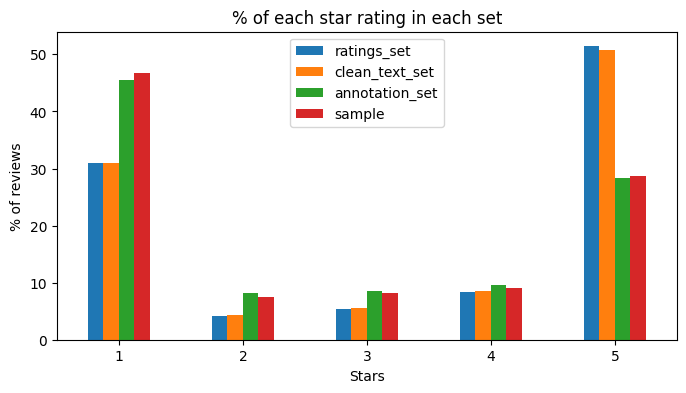

In [66]:
star_pct_all.plot(kind='bar', figsize=(8, 4))
plt.title('% of each star rating in each set')
plt.xlabel('Stars')
plt.ylabel('% of reviews')
plt.xticks(rotation=0)
plt.show()

In [67]:
star_counts_all = pd.concat({
    'ratings_set': pd.crosstab(df_ratings['year'], df_ratings['score']).stack(),
    'clean_text_set': pd.crosstab(df_clean_full['year'], df_clean_full['score']).stack(),
    'annotation_set': pd.crosstab(df_annotate_unique['year'], df_annotate_unique['score']).stack()}, axis=1)
star_counts_all

ratings_set  clean_text_set  annotation_set
year score                                             
2022 1            32544           27941           15212
     2             5653            5124            3401
     3             7814            6980            3869
     4            12820           11388            4445
     5            77277           65495           11569
2023 1            41996           36102           17638
     2             4024            3616            2417
     3             4337            3838            2227
     4             6291            5468            2259
     5            35513           30004            5504
2026 1            14519           13258            7840
     2             2315            2179            1466
     3             3039            2837            1553
     4             4958            4547            1853
     5            35375           31312            8221

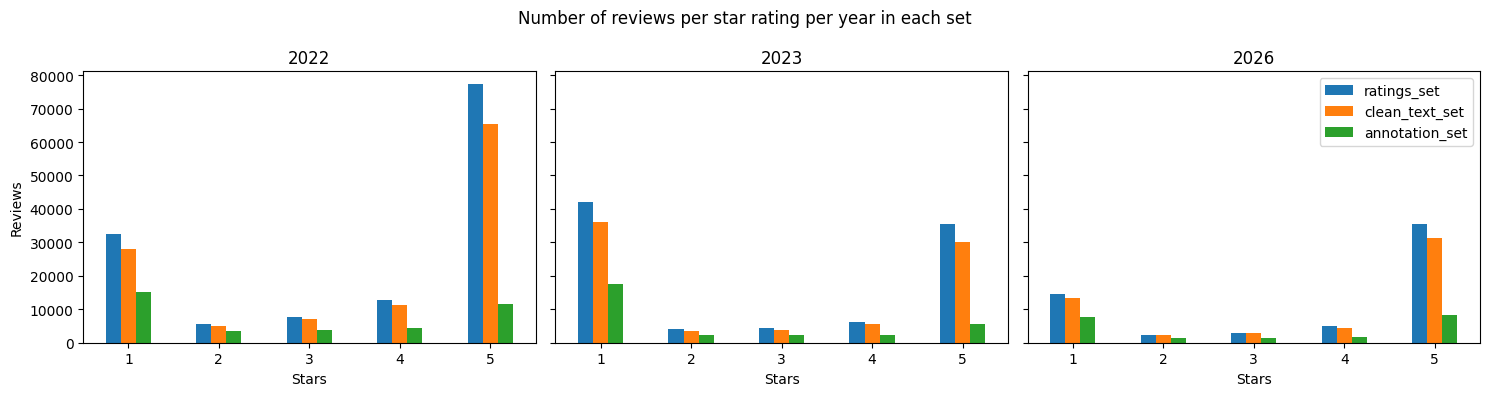

In [68]:
years = star_counts_all.index.get_level_values('year').unique()
fig, axes = plt.subplots(1, len(years), figsize=(15, 4), sharey=True)

for ax, year in zip(axes, years):
    star_counts_all.loc[year].plot(kind='bar', ax=ax, legend=False)
    ax.set_title(str(year))
    ax.set_xlabel('Stars')
    ax.tick_params(axis='x', rotation=0)

axes[0].set_ylabel('Reviews')
axes[-1].legend()
fig.suptitle('Number of reviews per star rating per year in each set')
plt.tight_layout()
plt.show()